# Project 1: Shark-Tuna ODE System

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Tuna, with no sharks

Each tuna has `b` babies per year:

$$T' = bT$$

This assumes every tuna is the same, every tuna can reproduce, and tuna only die by being eaten.

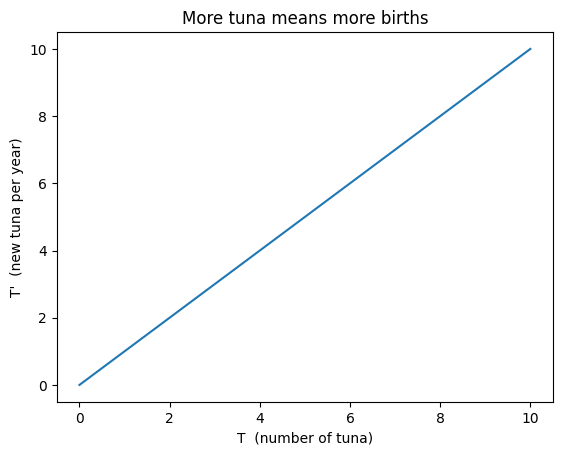

In [2]:
b = 1.0
T = np.linspace(0, 10, 100)

plt.plot(T, b * T)
plt.xlabel('T  (number of tuna)')
plt.ylabel("T'  (new tuna per year)")
plt.title('More tuna means more births')
plt.show()

# Sharks, with no tuna

With no food, sharks die at rate `d` and have no babies:

$$S' = -dS$$

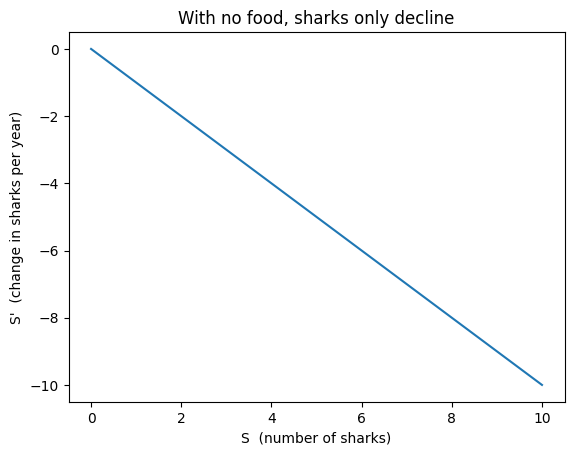

In [3]:
d = 1.0
S = np.linspace(0, 10, 100)

plt.plot(S, -d * S)
plt.xlabel('S  (number of sharks)')
plt.ylabel("S'  (change in sharks per year)")
plt.title('With no food, sharks only decline')
plt.show()

# Both together

Sharks and tuna meet at a rate that depends on $ST$. `beta` is the chance a meeting kills the tuna, and `m` is the sharks born per tuna eaten.

$$S' = m\beta ST - dS$$

$$T' = bT - \beta ST$$

These are the Lotka-Volterra equations. Every parameter is 1.

In [4]:
b = 1.0
d = 1.0
beta = 1.0
m = 1.0

def change(S, T):
    dS = m * beta * S * T - d * S
    dT = b * T - beta * S * T
    return dS, dT

# Time series

`solve_ivp` solves the ODE, starting from $S = 2$ and $T = 3$.

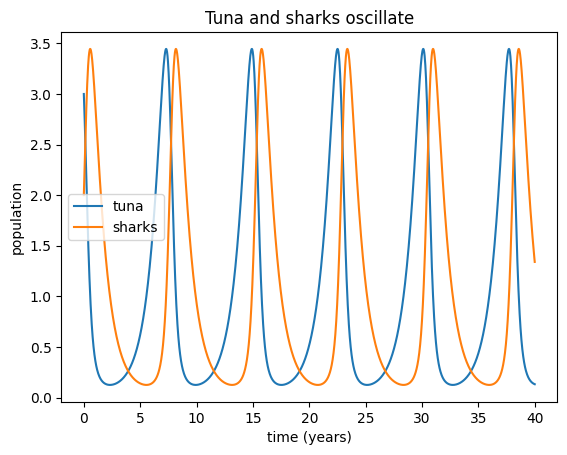

In [5]:
def rates(t, y):
    S, T = y
    return change(S, T)

def simulate(S0, T0, t_start, t_end):
    times = np.linspace(t_start, t_end, 2000)
    sol = solve_ivp(rates, [t_start, t_end], [S0, T0], t_eval=times, rtol=1e-8)
    return sol.t, sol.y[0], sol.y[1]

t, S, T = simulate(2, 3, 0, 40)

plt.plot(t, T, label='tuna')
plt.plot(t, S, label='sharks')
plt.xlabel('time (years)')
plt.ylabel('population')
plt.title('Tuna and sharks oscillate')
plt.legend()
plt.show()

# The limit cycle

Plot sharks against tuna instead of against time. The populations go around the same loop forever.

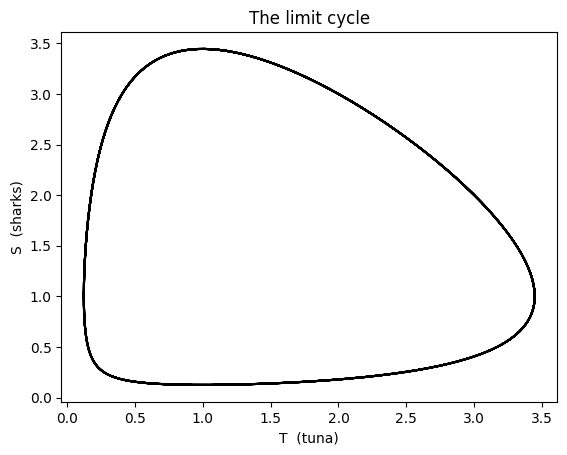

In [6]:
plt.plot(T, S, 'k')
plt.xlabel('T  (tuna)')
plt.ylabel('S  (sharks)')
plt.title('The limit cycle')
plt.show()

# Perturbations

Half the sharks are removed at once, $S \rightarrow \tfrac{1}{2}S$, and then the ODE carries on.
I do this at four phases of the cycle: the tuna peak, the shark peak, the tuna low, and the shark low.

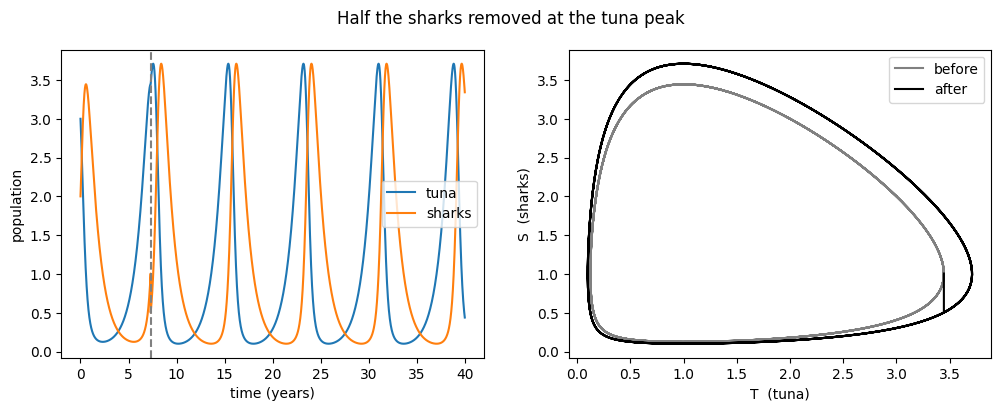

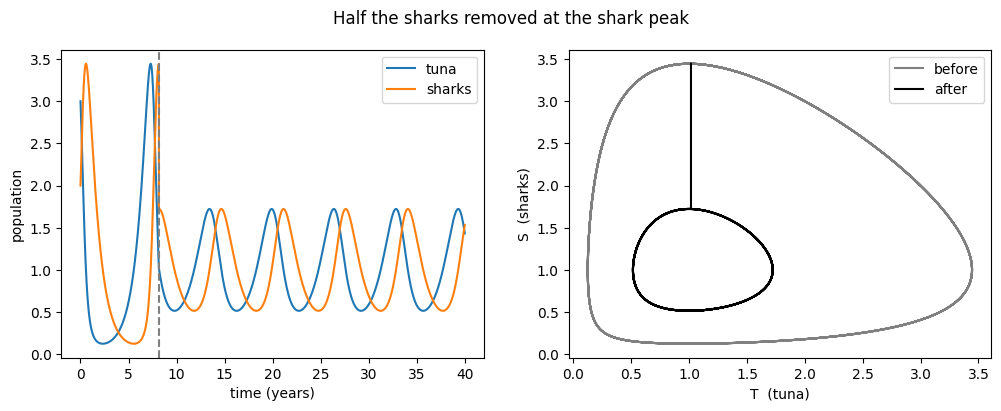

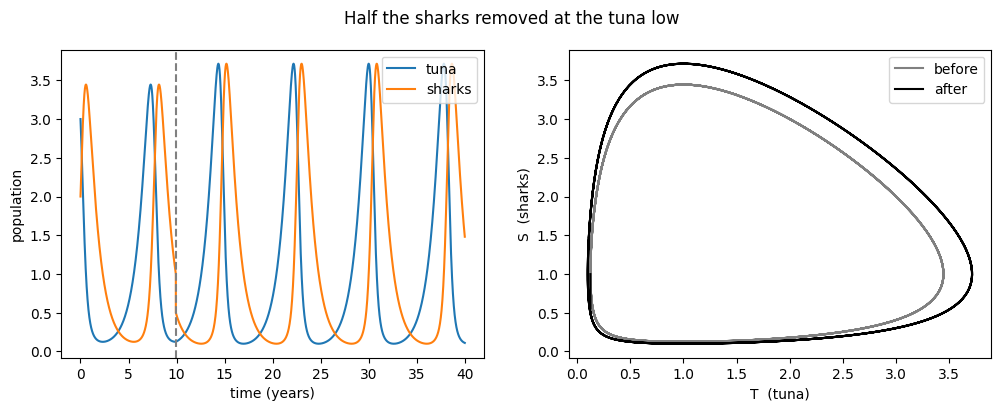

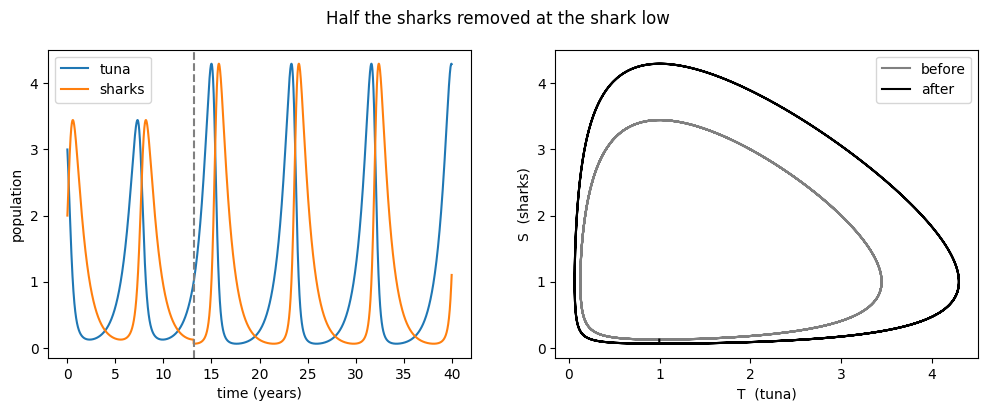

In [7]:
cycle = (t > 7) & (t < 15)
t_top_T = t[cycle][np.argmax(T[cycle])]
t_top = t[cycle][np.argmax(S[cycle])]
t_bottom_T = t[cycle][np.argmin(T[cycle])]
t_bottom = t[cycle][np.argmin(S[cycle])]

def perturb(t_kick, keep_S=0.5, keep_T=1.0):
    t1, S1, T1 = simulate(2, 3, 0, t_kick)
    t2, S2, T2 = simulate(S1[-1] * keep_S, T1[-1] * keep_T, t_kick, 40)
    return np.append(t1, t2), np.append(S1, S2), np.append(T1, T2)

for t_kick, name in [(t_top_T, 'tuna peak'), (t_top, 'shark peak'),
                     (t_bottom_T, 'tuna low'), (t_bottom, 'shark low')]:
    tp, Sp, Tp = perturb(t_kick)
    after = tp >= t_kick

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(tp, Tp, label='tuna')
    plt.plot(tp, Sp, label='sharks')
    plt.axvline(t_kick, color='gray', linestyle='--')
    plt.xlabel('time (years)')
    plt.ylabel('population')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(T, S, color='gray', label='before')
    plt.plot(Tp[after], Sp[after], 'k', label='after')
    plt.xlabel('T  (tuna)')
    plt.ylabel('S  (sharks)')
    plt.legend()

    plt.suptitle(f'Half the sharks removed at the {name}')
    plt.show()

# The vector field

At each point $(T, S)$, the ODE gives an arrow $(T', S')$ pointing where the populations go next. Every arrow is drawn the same length.

- $T' = 0$ on the line $S = b/\beta = 1$. Above it tuna shrink, below it they grow.
- $S' = 0$ on the line $T = d/(m\beta) = 1$. Right of it sharks grow, left of it they shrink.

The lines cross at $(1, 1)$, where nothing changes. The arrows circle it counterclockwise.

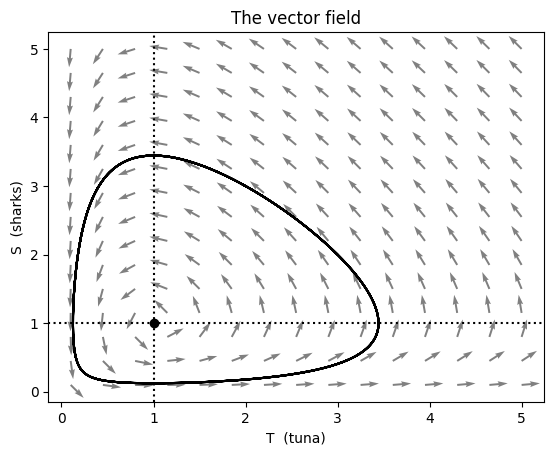

In [8]:
Tg, Sg = np.meshgrid(np.linspace(0.1, 5, 15), np.linspace(0.1, 5, 15))
dS, dT = change(Sg, Tg)
length = np.hypot(dT, dS)

plt.quiver(Tg, Sg, dT / length, dS / length, color='gray')
plt.axhline(b / beta, color='k', linestyle=':')
plt.axvline(d / (m * beta), color='k', linestyle=':')
plt.plot(1, 1, 'ko')
plt.plot(T, S, 'k')
plt.xlabel('T  (tuna)')
plt.ylabel('S  (sharks)')
plt.title('The vector field')
plt.show()

## Flow lines

The same arrows, joined into lines.

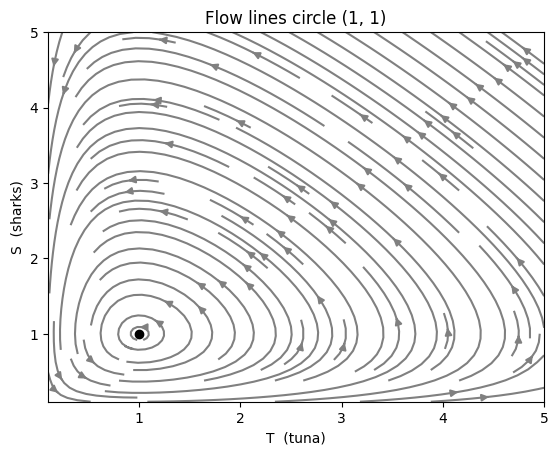

In [9]:
plt.streamplot(Tg, Sg, dT, dS, color='gray', density=1.2)
plt.plot(1, 1, 'ko')
plt.xlabel('T  (tuna)')
plt.ylabel('S  (sharks)')
plt.title('Flow lines circle (1, 1)')
plt.show()

# More perturbations

## Fishing the tuna

A boat takes half the tuna at once, $T \rightarrow \tfrac{1}{2}T$, at the top and the bottom of the tuna cycle.

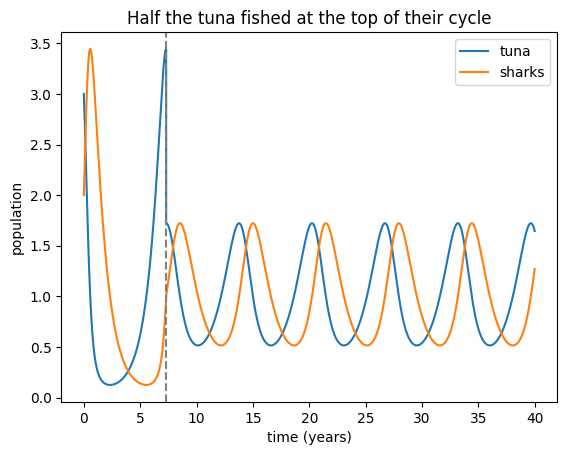

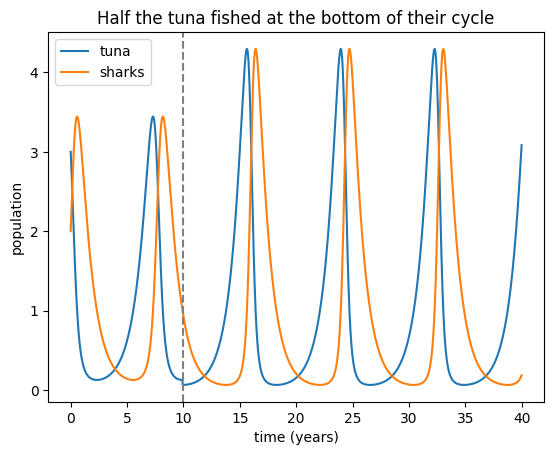

In [10]:
for t_kick, name in [(t_top_T, 'top'), (t_bottom_T, 'bottom')]:
    tp, Sp, Tp = perturb(t_kick, keep_S=1.0, keep_T=0.5)
    plt.plot(tp, Tp, label='tuna')
    plt.plot(tp, Sp, label='sharks')
    plt.axvline(t_kick, color='gray', linestyle='--')
    plt.xlabel('time (years)')
    plt.ylabel('population')
    plt.title(f'Half the tuna fished at the {name} of their cycle')
    plt.legend()
    plt.show()

## Kicks on the flow lines

A kick doesn't change the ODE, so the arrows stay the same. It just moves the dot onto a new loop.

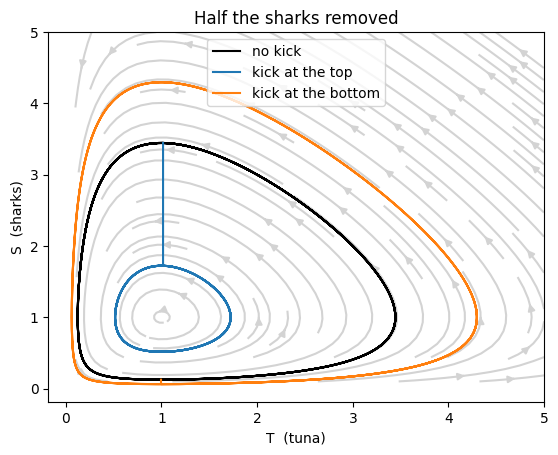

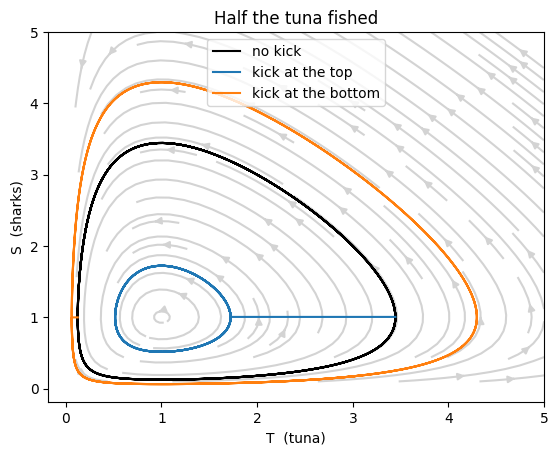

In [11]:
for title, keep_S, keep_T, times in [('Half the sharks removed', 0.5, 1.0, [t_top, t_bottom]),
                                     ('Half the tuna fished', 1.0, 0.5, [t_top_T, t_bottom_T])]:
    plt.streamplot(Tg, Sg, dT, dS, color='lightgray')
    plt.plot(T, S, 'k', label='no kick')
    for t_kick, name in zip(times, ['top', 'bottom']):
        tp, Sp, Tp = perturb(t_kick, keep_S, keep_T)
        after = tp >= t_kick
        plt.plot(Tp[after], Sp[after], label=f'kick at the {name}')
    plt.xlabel('T  (tuna)')
    plt.ylabel('S  (sharks)')
    plt.title(title)
    plt.legend()
    plt.show()

## Fishing all year round

Fishing all the time goes inside the ODE, so it changes the arrows:

$$S' = m\beta ST - dS - f_S S$$

$$T' = bT - \beta ST - f_T T$$

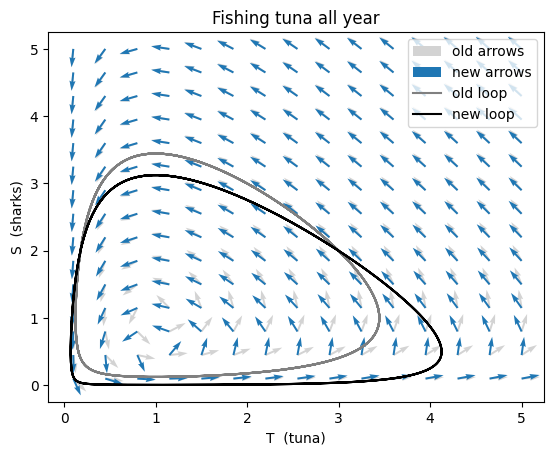

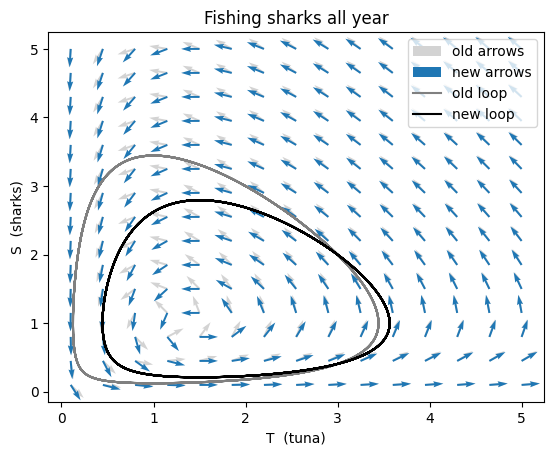

In [12]:
def change_fished(S, T, f_S, f_T):
    dS, dT = change(S, T)
    return dS - f_S * S, dT - f_T * T

def rates_fished(t, y, f_S, f_T):
    S, T = y
    return change_fished(S, T, f_S, f_T)

for title, f_S, f_T in [('Fishing tuna all year', 0, 0.5),
                        ('Fishing sharks all year', 0.5, 0)]:
    dS_f, dT_f = change_fished(Sg, Tg, f_S, f_T)
    length_f = np.hypot(dT_f, dS_f)
    sol = solve_ivp(rates_fished, [0, 40], [2, 3], args=(f_S, f_T), t_eval=np.linspace(0, 40, 2000), rtol=1e-8)

    plt.quiver(Tg, Sg, dT / length, dS / length, color='lightgray', label='old arrows')
    plt.quiver(Tg, Sg, dT_f / length_f, dS_f / length_f, color='C0', label='new arrows')
    plt.plot(T, S, color='gray', label='old loop')
    plt.plot(sol.y[1], sol.y[0], 'k', label='new loop')
    plt.xlabel('T  (tuna)')
    plt.ylabel('S  (sharks)')
    plt.title(title)
    plt.legend()
    plt.show()

## Complete decline

One population is wiped out. With no sharks, $T' = bT$, so the tuna grow forever. With no tuna, $S' = -dS$, so the sharks die out.
On the flow lines, the dot falls onto an edge and never comes back.

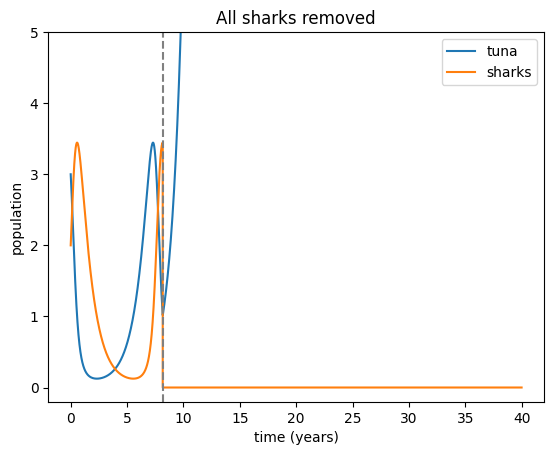

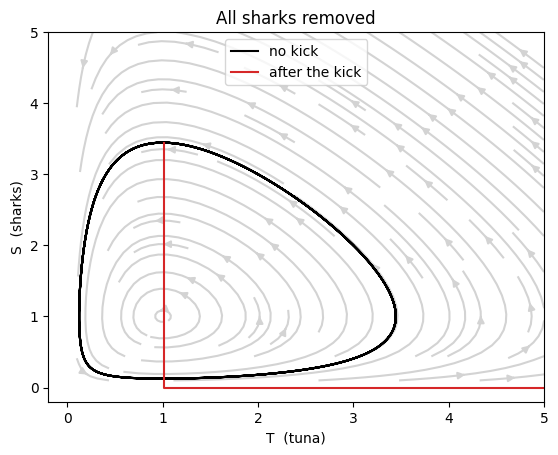

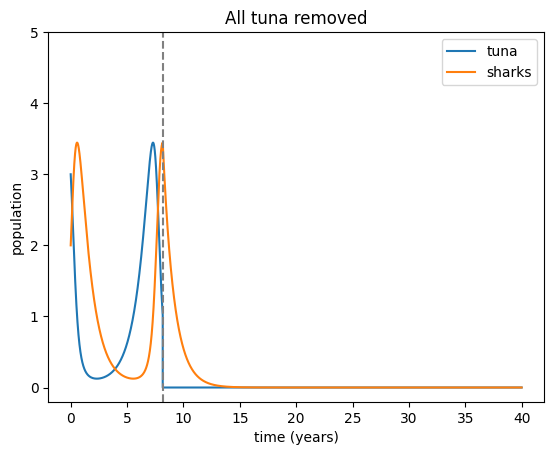

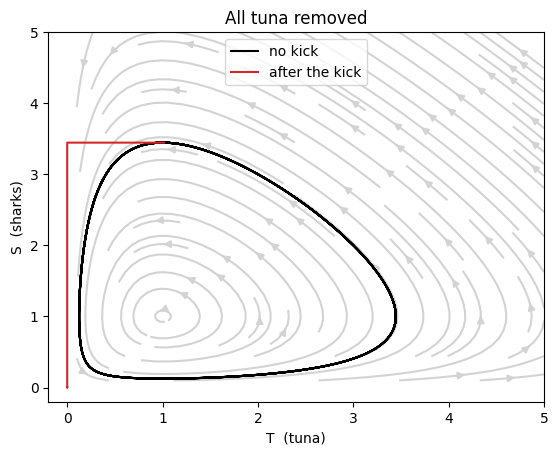

In [13]:
for title, keep_S, keep_T in [('All sharks removed', 0, 1),
                              ('All tuna removed', 1, 0)]:
    tp, Sp, Tp = perturb(t_top, keep_S, keep_T)
    after = tp >= t_top

    plt.plot(tp, Tp, 'C0', label='tuna')
    plt.plot(tp, Sp, 'C1', label='sharks')
    plt.axvline(t_top, color='gray', linestyle='--')
    plt.ylim(-0.2, 5)
    plt.xlabel('time (years)')
    plt.ylabel('population')
    plt.title(title)
    plt.legend()
    plt.show()

    plt.streamplot(Tg, Sg, dT, dS, color='lightgray')
    plt.plot(T, S, 'k', label='no kick')
    plt.plot(Tp[after], Sp[after], 'C3', label='after the kick')
    plt.xlim(-0.2, 5)
    plt.ylim(-0.2, 5)
    plt.xlabel('T  (tuna)')
    plt.ylabel('S  (sharks)')
    plt.title(title)
    plt.legend()
    plt.show()

# The math, simply

- The ODE says how fast each population is changing right now.
- `solve_ivp` adds up lots of tiny changes to get the populations over time.
- Plotting sharks against tuna gives the limit cycle.
- A kick moves the populations onto a new loop. Where on the loop the kick happens decides if the new loop is bigger or smaller.
- Each arrow is the ODE at one point. It shows where the populations go next.
- A kick doesn't change the ODE, so the arrows stay the same.
- Fishing all year changes the ODE, so the arrows change.
- If one population hits zero, it can't come back.